In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.insert(0, "..")

import json
import numpy as np

from sst2 import *
from part1 import analysis, bpe, clslib, experiment, loglin, smlp, utils
from helpers import fold_metrics, mlp2_cross_validation

<h4>load training data. Get tokenizer. Get crossval folds.</h4>

In [2]:
train, valid, test = load_sst2()

bpe_tokenzier = get_tokenizer(train)

cv_train = get_cv_splits(train)[0]

<h4>Experiments: BoW with log-linear, MLP and MLP2</h4>

In [3]:
encoder = BagOfWords(bpe_tokenzier)

In [4]:
# BoW + LOGLIN
bow_loglin = experiment.cross_validation_experiment(cv_train, CLASSES, encoder, 'logistic', save_to=f"results/models/bow_loglin/1", loglin_args={"max_iter": 1000})

  0%|          | 0/5 [00:00<?, ?it/s]

/Users/efearas/nlp1-group15/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/efearas/nlp1-group15/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/efearas/nlp1-group15/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/efearas/nlp1-group15/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will 

In [5]:
# BoW + singleMLP
bow_mlp = experiment.cross_validation_experiment(cv_train, CLASSES, encoder, 'mlp', save_to=f"results/models/bow_mlp/1", smlp_args={"num_epochs": 5, "dropout": 0.3})

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 88.024 seconds
Dataloader done! Time taken: 4.546 seconds
Training...


  0%|          | 0/5 [00:00<?, ?it/s]

/Users/efearas/nlp1-group15/part1/smlp.py:68: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:252.)
  indices = torch.tensor([x.row, x.col], dtype=torch.long)
/Users/efearas/nlp1-group15/part1/smlp.py:71: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:923.)
  return torch.sparse_coo_tensor(indices, values, size=x.shape).coalesce()


Epoch 01 | train loss: 0.3891 | train acc: 0.8241 | val loss: 0.2758 | val acc: 0.8878
Epoch 02 | train loss: 0.2332 | train acc: 0.9071 | val loss: 0.2340 | val acc: 0.9082
Epoch 03 | train loss: 0.1738 | train acc: 0.9336 | val loss: 0.2214 | val acc: 0.9154
Epoch 04 | train loss: 0.1348 | train acc: 0.9496 | val loss: 0.2189 | val acc: 0.9215
Epoch 05 | train loss: 0.1105 | train acc: 0.9601 | val loss: 0.2203 | val acc: 0.9251
Training done! Time taken: 21.351 seconds
Transforming documents...
Document transformation done! Time taken: 89.276 seconds
Dataloader done! Time taken: 4.802 seconds
Training...


  0%|          | 0/5 [00:00<?, ?it/s]

... (3 outputs left out)

  0%|          | 0/5 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.3868 | train acc: 0.8240 | val loss: 0.2889 | val acc: 0.8801
Epoch 02 | train loss: 0.2289 | train acc: 0.9081 | val loss: 0.2549 | val acc: 0.9013
Epoch 03 | train loss: 0.1721 | train acc: 0.9340 | val loss: 0.2408 | val acc: 0.9109
Epoch 04 | train loss: 0.1346 | train acc: 0.9494 | val loss: 0.2362 | val acc: 0.9181
Epoch 05 | train loss: 0.1066 | train acc: 0.9608 | val loss: 0.2518 | val acc: 0.9201
Training done! Time taken: 18.420 seconds
Transforming documents...
Document transformation done! Time taken: 88.215 seconds
Dataloader done! Time taken: 4.726 seconds
Training...


  0%|          | 0/5 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.3872 | train acc: 0.8239 | val loss: 0.2784 | val acc: 0.8886
Epoch 02 | train loss: 0.2280 | train acc: 0.9091 | val loss: 0.2417 | val acc: 0.9059
Epoch 03 | train loss: 0.1716 | train acc: 0.9338 | val loss: 0.2308 | val acc: 0.9135
Epoch 04 | train loss: 0.1335 | train acc: 0.9514 | val loss: 0.2287 | val acc: 0.9200
Epoch 05 | train loss: 0.1060 | train acc: 0.9628 | val loss: 0.2431 | val acc: 0.9202
Training done! Time taken: 18.396 seconds


In [6]:
# BoW + MLP2
bow_mlp2 = mlp2_cross_validation(cv_train, BagOfWords, bpe_tokenzier, save_to="results/models/bow_mlp2/1")

Transforming documents...
Document transformation done! Time taken: 88.345 seconds
Dataloader done! Time taken: 4.737 seconds
Training...


  0%|          | 0/5 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.3818 | train acc: 0.8251 | val loss: 0.2599 | val acc: 0.8928
Epoch 02 | train loss: 0.2092 | train acc: 0.9201 | val loss: 0.2201 | val acc: 0.9157
Epoch 03 | train loss: 0.1430 | train acc: 0.9482 | val loss: 0.2170 | val acc: 0.9199
Epoch 04 | train loss: 0.1064 | train acc: 0.9612 | val loss: 0.2271 | val acc: 0.9251
Epoch 05 | train loss: 0.0784 | train acc: 0.9719 | val loss: 0.2434 | val acc: 0.9291
Training done! Time taken: 21.501 seconds
Transforming documents...
Document transformation done! Time taken: 88.459 seconds
Dataloader done! Time taken: 4.824 seconds
Training...


  0%|          | 0/5 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.3796 | train acc: 0.8259 | val loss: 0.2686 | val acc: 0.8891
Epoch 02 | train loss: 0.2086 | train acc: 0.9207 | val loss: 0.2328 | val acc: 0.9076
Epoch 03 | train loss: 0.1423 | train acc: 0.9486 | val loss: 0.2301 | val acc: 0.9167
Epoch 04 | train loss: 0.1054 | train acc: 0.9621 | val loss: 0.2339 | val acc: 0.9212
Epoch 05 | train loss: 0.0792 | train acc: 0.9715 | val loss: 0.2378 | val acc: 0.9255
Training done! Time taken: 18.961 seconds
Transforming documents...
Document transformation done! Time taken: 88.507 seconds
Dataloader done! Time taken: 4.696 seconds
Training...


  0%|          | 0/5 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.3798 | train acc: 0.8234 | val loss: 0.2632 | val acc: 0.8954
Epoch 02 | train loss: 0.2085 | train acc: 0.9209 | val loss: 0.2274 | val acc: 0.9157
Epoch 03 | train loss: 0.1418 | train acc: 0.9488 | val loss: 0.2292 | val acc: 0.9200
Epoch 04 | train loss: 0.1029 | train acc: 0.9630 | val loss: 0.2382 | val acc: 0.9242
Epoch 05 | train loss: 0.0790 | train acc: 0.9713 | val loss: 0.2606 | val acc: 0.9253
Training done! Time taken: 18.986 seconds
Transforming documents...
Document transformation done! Time taken: 88.362 seconds
Dataloader done! Time taken: 4.601 seconds
Training...


  0%|          | 0/5 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.3786 | train acc: 0.8249 | val loss: 0.2765 | val acc: 0.8867
Epoch 02 | train loss: 0.2028 | train acc: 0.9235 | val loss: 0.2409 | val acc: 0.9131
Epoch 03 | train loss: 0.1403 | train acc: 0.9488 | val loss: 0.2390 | val acc: 0.9168
Epoch 04 | train loss: 0.1025 | train acc: 0.9630 | val loss: 0.2532 | val acc: 0.9209
Epoch 05 | train loss: 0.0778 | train acc: 0.9725 | val loss: 0.2664 | val acc: 0.9259
Training done! Time taken: 21.102 seconds
Transforming documents...
Document transformation done! Time taken: 87.874 seconds
Dataloader done! Time taken: 4.872 seconds
Training...


  0%|          | 0/5 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.3771 | train acc: 0.8272 | val loss: 0.2638 | val acc: 0.8961
Epoch 02 | train loss: 0.2038 | train acc: 0.9225 | val loss: 0.2306 | val acc: 0.9133
Epoch 03 | train loss: 0.1412 | train acc: 0.9493 | val loss: 0.2282 | val acc: 0.9191
Epoch 04 | train loss: 0.1023 | train acc: 0.9635 | val loss: 0.2443 | val acc: 0.9197
Epoch 05 | train loss: 0.0760 | train acc: 0.9728 | val loss: 0.2660 | val acc: 0.9218
Training done! Time taken: 20.664 seconds


In [7]:
# Save accuracy, precision, recall and F1 per fold
results = {
    "bow_loglin": fold_metrics(bow_loglin, cv_train),
    "bow_mlp": fold_metrics(bow_mlp, cv_train),
    "bow_mlp2": fold_metrics(bow_mlp2, cv_train),
}

with open("results/bow_accuracies.json", "w") as f:
    json.dump(results, f, indent=2)

print("saved to results/bow_accuracies.json")

saved to results/bow_accuracies.json


<h4>Experiments: TokenIndicator with log-linear, MLP and MLP2</h4>

In [8]:
ti_encoder = TokenIndicator(bpe_tokenzier)

In [9]:
# TokenIndicator + LOGLIN
ti_loglin = experiment.cross_validation_experiment(cv_train, CLASSES, ti_encoder, 'logistic', save_to="results/models/ti_loglin/1", loglin_args={"max_iter": 1000})

  0%|          | 0/5 [00:00<?, ?it/s]

/Users/efearas/nlp1-group15/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/efearas/nlp1-group15/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/efearas/nlp1-group15/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/efearas/nlp1-group15/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will 

In [10]:
# TokenIndicator + singleMLP
ti_mlp = experiment.cross_validation_experiment(cv_train, CLASSES, ti_encoder, 'mlp', save_to="results/models/ti_mlp/1", smlp_args={"num_epochs": 5, "dropout": 0.3})

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 88.611 seconds
Dataloader done! Time taken: 4.541 seconds
Training...


  0%|          | 0/5 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.3907 | train acc: 0.8236 | val loss: 0.2759 | val acc: 0.8849
Epoch 02 | train loss: 0.2324 | train acc: 0.9078 | val loss: 0.2351 | val acc: 0.9064
Epoch 03 | train loss: 0.1745 | train acc: 0.9323 | val loss: 0.2223 | val acc: 0.9157
Epoch 04 | train loss: 0.1350 | train acc: 0.9501 | val loss: 0.2164 | val acc: 0.9216
Epoch 05 | train loss: 0.1062 | train acc: 0.9610 | val loss: 0.2223 | val acc: 0.9235
Training done! Time taken: 18.315 seconds
Transforming documents...
Document transformation done! Time taken: 92.270 seconds
Dataloader done! Time taken: 4.696 seconds
Training...


  0%|          | 0/5 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.3859 | train acc: 0.8249 | val loss: 0.2939 | val acc: 0.8767
Epoch 02 | train loss: 0.2306 | train acc: 0.9070 | val loss: 0.2495 | val acc: 0.8996
Epoch 03 | train loss: 0.1741 | train acc: 0.9327 | val loss: 0.2322 | val acc: 0.9125
Epoch 04 | train loss: 0.1347 | train acc: 0.9500 | val loss: 0.2294 | val acc: 0.9160
Epoch 05 | train loss: 0.1084 | train acc: 0.9609 | val loss: 0.2293 | val acc: 0.9207
Training done! Time taken: 18.514 seconds
Transforming documents...
Document transformation done! Time taken: 88.711 seconds
Dataloader done! Time taken: 4.632 seconds
Training...


... (2 outputs left out)

  0%|          | 0/5 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.3869 | train acc: 0.8230 | val loss: 0.2926 | val acc: 0.8838
Epoch 02 | train loss: 0.2280 | train acc: 0.9080 | val loss: 0.2532 | val acc: 0.9016
Epoch 03 | train loss: 0.1696 | train acc: 0.9355 | val loss: 0.2395 | val acc: 0.9124
Epoch 04 | train loss: 0.1305 | train acc: 0.9519 | val loss: 0.2348 | val acc: 0.9195
Epoch 05 | train loss: 0.1037 | train acc: 0.9631 | val loss: 0.2444 | val acc: 0.9230
Training done! Time taken: 17.149 seconds
Transforming documents...
Document transformation done! Time taken: 86.845 seconds
Dataloader done! Time taken: 4.810 seconds
Training...


  0%|          | 0/5 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.3891 | train acc: 0.8246 | val loss: 0.2814 | val acc: 0.8849
Epoch 02 | train loss: 0.2328 | train acc: 0.9070 | val loss: 0.2428 | val acc: 0.9047
Epoch 03 | train loss: 0.1745 | train acc: 0.9326 | val loss: 0.2291 | val acc: 0.9137
Epoch 04 | train loss: 0.1353 | train acc: 0.9504 | val loss: 0.2304 | val acc: 0.9177
Epoch 05 | train loss: 0.1088 | train acc: 0.9617 | val loss: 0.2360 | val acc: 0.9203
Training done! Time taken: 17.558 seconds


In [11]:
# TokenIndicator + MLP2
ti_mlp2 = mlp2_cross_validation(cv_train, TokenIndicator, bpe_tokenzier, save_to="results/models/ti_mlp2/1")

Transforming documents...
Document transformation done! Time taken: 86.870 seconds
Dataloader done! Time taken: 4.737 seconds
Training...


  0%|          | 0/5 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.3812 | train acc: 0.8259 | val loss: 0.2561 | val acc: 0.8976
Epoch 02 | train loss: 0.2089 | train acc: 0.9200 | val loss: 0.2211 | val acc: 0.9162
Epoch 03 | train loss: 0.1432 | train acc: 0.9482 | val loss: 0.2169 | val acc: 0.9224
Epoch 04 | train loss: 0.1033 | train acc: 0.9633 | val loss: 0.2194 | val acc: 0.9255
Epoch 05 | train loss: 0.0761 | train acc: 0.9727 | val loss: 0.2403 | val acc: 0.9266
Training done! Time taken: 18.405 seconds
Transforming documents...
Document transformation done! Time taken: 86.636 seconds
Dataloader done! Time taken: 4.744 seconds
Training...


  0%|          | 0/5 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.3806 | train acc: 0.8247 | val loss: 0.2710 | val acc: 0.8902
Epoch 02 | train loss: 0.2079 | train acc: 0.9222 | val loss: 0.2298 | val acc: 0.9109
Epoch 03 | train loss: 0.1410 | train acc: 0.9490 | val loss: 0.2160 | val acc: 0.9203
Epoch 04 | train loss: 0.1026 | train acc: 0.9642 | val loss: 0.2287 | val acc: 0.9223
Epoch 05 | train loss: 0.0762 | train acc: 0.9716 | val loss: 0.2593 | val acc: 0.9220
Training done! Time taken: 17.800 seconds
Transforming documents...
Document transformation done! Time taken: 87.018 seconds
Dataloader done! Time taken: 4.726 seconds
Training...


  0%|          | 0/5 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.3816 | train acc: 0.8214 | val loss: 0.2622 | val acc: 0.8968
Epoch 02 | train loss: 0.2074 | train acc: 0.9196 | val loss: 0.2291 | val acc: 0.9157
Epoch 03 | train loss: 0.1399 | train acc: 0.9489 | val loss: 0.2233 | val acc: 0.9214
Epoch 04 | train loss: 0.1008 | train acc: 0.9636 | val loss: 0.2391 | val acc: 0.9235
Epoch 05 | train loss: 0.0771 | train acc: 0.9724 | val loss: 0.2509 | val acc: 0.9249
Training done! Time taken: 17.849 seconds
Transforming documents...
Document transformation done! Time taken: 86.932 seconds
Dataloader done! Time taken: 4.800 seconds
Training...


  0%|          | 0/5 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.3747 | train acc: 0.8311 | val loss: 0.2716 | val acc: 0.8889
Epoch 02 | train loss: 0.2064 | train acc: 0.9209 | val loss: 0.2381 | val acc: 0.9113
Epoch 03 | train loss: 0.1385 | train acc: 0.9500 | val loss: 0.2367 | val acc: 0.9209
Epoch 04 | train loss: 0.1009 | train acc: 0.9642 | val loss: 0.2507 | val acc: 0.9243
Epoch 05 | train loss: 0.0741 | train acc: 0.9728 | val loss: 0.2856 | val acc: 0.9238
Training done! Time taken: 18.100 seconds
Transforming documents...
Document transformation done! Time taken: 1996.125 seconds
Dataloader done! Time taken: 5.033 seconds
Training...


  0%|          | 0/5 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.3763 | train acc: 0.8265 | val loss: 0.2686 | val acc: 0.8929
Epoch 02 | train loss: 0.2071 | train acc: 0.9224 | val loss: 0.2298 | val acc: 0.9140
Epoch 03 | train loss: 0.1397 | train acc: 0.9498 | val loss: 0.2274 | val acc: 0.9194
Epoch 04 | train loss: 0.1006 | train acc: 0.9633 | val loss: 0.2386 | val acc: 0.9231
Epoch 05 | train loss: 0.0752 | train acc: 0.9731 | val loss: 0.2742 | val acc: 0.9226
Training done! Time taken: 17.974 seconds


In [12]:
# Save accuracy, precision, recall and F1 per fold
results = {
    "ti_loglin": fold_metrics(ti_loglin, cv_train),
    "ti_mlp": fold_metrics(ti_mlp, cv_train),
    "ti_mlp2": fold_metrics(ti_mlp2, cv_train),
}

with open("results/ti_accuracies.json", "w") as f:
    json.dump(results, f, indent=2)

print("saved to results/ti_accuracies.json")

saved to results/ti_accuracies.json


<h4>Experiments: TF-IDF (unigram) with log-linear, MLP and MLP2</h4>

In [13]:
def tfidf_cross_validation(folds, model, save_to):
    result = {"models": {}, "predictions": {}, "accuracies": {}}

    for f, s in folds.items():
        tfidf_encoder = TFIDFunigram(bpe_tokenzier)
        tfidf_encoder.fit([text for text, _ in s["training"]])

        f_result = experiment.cross_validation_experiment({f: s}, CLASSES, tfidf_encoder, model, save_to=save_to,
                                                          loglin_args={"max_iter": 1000}, smlp_args={"num_epochs": 5, "dropout": 0.3})

        for key in result:
            result[key][f] = f_result[key][f]

    return result

In [14]:
# TF-IDF + LOGLIN
tfidf_loglin = tfidf_cross_validation(cv_train, 'logistic', save_to="results/models/tfidf_loglin/1")

  0%|          | 0/1 [00:00<?, ?it/s]

/Users/efearas/nlp1-group15/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


  0%|          | 0/1 [00:00<?, ?it/s]

/Users/efearas/nlp1-group15/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


  0%|          | 0/1 [00:00<?, ?it/s]

/Users/efearas/nlp1-group15/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


  0%|          | 0/1 [00:00<?, ?it/s]

/Users/efearas/nlp1-group15/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


  0%|          | 0/1 [00:00<?, ?it/s]

/Users/efearas/nlp1-group15/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


In [15]:
# TF-IDF + singleMLP
tfidf_mlp = tfidf_cross_validation(cv_train, 'mlp', save_to="results/models/tfidf_mlp/1")

  0%|          | 0/1 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 3.269 seconds
Dataloader done! Time taken: 4.133 seconds
Training...


  0%|          | 0/5 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.3966 | train acc: 0.8141 | val loss: 0.2940 | val acc: 0.8757
Epoch 02 | train loss: 0.2618 | train acc: 0.8919 | val loss: 0.2668 | val acc: 0.8893
Epoch 03 | train loss: 0.2175 | train acc: 0.9133 | val loss: 0.2511 | val acc: 0.9036
Epoch 04 | train loss: 0.1814 | train acc: 0.9301 | val loss: 0.2390 | val acc: 0.9108
Epoch 05 | train loss: 0.1486 | train acc: 0.9454 | val loss: 0.2349 | val acc: 0.9175
Training done! Time taken: 1163.259 seconds


  0%|          | 0/1 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 14.300 seconds
Dataloader done! Time taken: 10.186 seconds
Training...


... (10 outputs left out)

  0%|          | 0/1 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 3.228 seconds
Dataloader done! Time taken: 4.675 seconds
Training...


  0%|          | 0/5 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.3962 | train acc: 0.8131 | val loss: 0.3003 | val acc: 0.8733
Epoch 02 | train loss: 0.2585 | train acc: 0.8933 | val loss: 0.2699 | val acc: 0.8909
Epoch 03 | train loss: 0.2124 | train acc: 0.9159 | val loss: 0.2540 | val acc: 0.9004
Epoch 04 | train loss: 0.1737 | train acc: 0.9339 | val loss: 0.2476 | val acc: 0.9096
Epoch 05 | train loss: 0.1401 | train acc: 0.9482 | val loss: 0.2424 | val acc: 0.9166
Training done! Time taken: 20.380 seconds


In [16]:
# TF-IDF + MLP2
tfidf_mlp2 = mlp2_cross_validation(cv_train, TFIDFunigram, bpe_tokenzier, save_to="results/models/tfidf_mlp2/1")

Transforming documents...
Document transformation done! Time taken: 3.114 seconds
Dataloader done! Time taken: 4.678 seconds
Training...


  0%|          | 0/5 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.3805 | train acc: 0.8222 | val loss: 0.2698 | val acc: 0.8890
Epoch 02 | train loss: 0.2246 | train acc: 0.9119 | val loss: 0.2286 | val acc: 0.9113
Epoch 03 | train loss: 0.1554 | train acc: 0.9426 | val loss: 0.2137 | val acc: 0.9222
Epoch 04 | train loss: 0.1114 | train acc: 0.9608 | val loss: 0.2260 | val acc: 0.9246
Epoch 05 | train loss: 0.0865 | train acc: 0.9694 | val loss: 0.2303 | val acc: 0.9265
Training done! Time taken: 19.040 seconds
Transforming documents...
Document transformation done! Time taken: 3.093 seconds
Dataloader done! Time taken: 4.515 seconds
Training...


  0%|          | 0/5 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.3791 | train acc: 0.8221 | val loss: 0.2786 | val acc: 0.8854
Epoch 02 | train loss: 0.2198 | train acc: 0.9135 | val loss: 0.2388 | val acc: 0.9056
Epoch 03 | train loss: 0.1533 | train acc: 0.9436 | val loss: 0.2310 | val acc: 0.9154
Epoch 04 | train loss: 0.1102 | train acc: 0.9613 | val loss: 0.2338 | val acc: 0.9194
Epoch 05 | train loss: 0.0843 | train acc: 0.9693 | val loss: 0.2503 | val acc: 0.9226
Training done! Time taken: 19.562 seconds
Transforming documents...
Document transformation done! Time taken: 3.116 seconds
Dataloader done! Time taken: 4.539 seconds
Training...


  0%|          | 0/5 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.3824 | train acc: 0.8219 | val loss: 0.2797 | val acc: 0.8825
Epoch 02 | train loss: 0.2254 | train acc: 0.9124 | val loss: 0.2362 | val acc: 0.9092
Epoch 03 | train loss: 0.1558 | train acc: 0.9432 | val loss: 0.2249 | val acc: 0.9199
Epoch 04 | train loss: 0.1119 | train acc: 0.9614 | val loss: 0.2382 | val acc: 0.9204
Epoch 05 | train loss: 0.0857 | train acc: 0.9703 | val loss: 0.2545 | val acc: 0.9218
Training done! Time taken: 19.423 seconds
Transforming documents...
Document transformation done! Time taken: 3.164 seconds
Dataloader done! Time taken: 4.309 seconds
Training...


  0%|          | 0/5 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.3780 | train acc: 0.8230 | val loss: 0.2841 | val acc: 0.8843
Epoch 02 | train loss: 0.2205 | train acc: 0.9151 | val loss: 0.2461 | val acc: 0.9071
Epoch 03 | train loss: 0.1494 | train acc: 0.9441 | val loss: 0.2470 | val acc: 0.9128
Epoch 04 | train loss: 0.1086 | train acc: 0.9611 | val loss: 0.2568 | val acc: 0.9191
Epoch 05 | train loss: 0.0814 | train acc: 0.9708 | val loss: 0.2768 | val acc: 0.9228
Training done! Time taken: 20.082 seconds
Transforming documents...
Document transformation done! Time taken: 3.134 seconds
Dataloader done! Time taken: 4.638 seconds
Training...


  0%|          | 0/5 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.3798 | train acc: 0.8206 | val loss: 0.2773 | val acc: 0.8857
Epoch 02 | train loss: 0.2194 | train acc: 0.9151 | val loss: 0.2420 | val acc: 0.9060
Epoch 03 | train loss: 0.1501 | train acc: 0.9460 | val loss: 0.2350 | val acc: 0.9171
Epoch 04 | train loss: 0.1075 | train acc: 0.9621 | val loss: 0.2396 | val acc: 0.9197
Epoch 05 | train loss: 0.0821 | train acc: 0.9717 | val loss: 0.2531 | val acc: 0.9235
Training done! Time taken: 19.590 seconds


In [17]:
# Save accuracy, precision, recall and F1 per fold
results = {
    "tfidf_loglin": fold_metrics(tfidf_loglin, cv_train),
    "tfidf_mlp": fold_metrics(tfidf_mlp, cv_train),
    "tfidf_mlp2": fold_metrics(tfidf_mlp2, cv_train),
}

with open("results/tfidf_accuracies.json", "w") as f:
    json.dump(results, f, indent=2)

print("saved to results/tfidf_accuracies.json")

saved to results/tfidf_accuracies.json


<h4>Results: all representations × architectures</h4>

In [18]:
import pandas as pd

# fold accuracies of every system, from the saved JSONs
accs = {}
for rep in ["ti", "bow", "tfidf"]:
    with open(f"results/{rep}_accuracies.json") as f:
        for name, metrics in json.load(f).items():
            accs[name] = metrics["accuracy"]

table = pd.DataFrame(accs).T
table["mean"] = table.mean(axis=1)
table.round(4)

,0,1,2,3,4,mean
ti_loglin,0.8793,0.8724,0.8781,0.8766,0.8804,0.8774
ti_mlp,0.9216,0.9207,0.9180,0.9195,0.9137,0.9187
ti_mlp2,0.9224,0.9203,0.9214,0.9209,0.9194,0.9209
bow_loglin,0.8797,0.8730,0.8789,0.8763,0.8805,0.8777
bow_mlp,0.9215,0.9151,0.9198,0.9181,0.9200,0.9189
bow_mlp2,0.9199,0.9167,0.9157,0.9168,0.9191,0.9176
tfidf_loglin,0.8705,0.8670,0.8729,0.8682,0.8744,0.8706
tfidf_mlp,0.9175,0.9122,0.9151,0.9033,0.9166,0.9130
tfidf_mlp2,0.9222,0.9154,0.9199,0.9071,0.9171,0.9163


<h4>Bayesian estimation with a ROPE</h4>

ROPE = ±0.005 (0.5 accuracy points), as in the tutorial: in NLP, gains below ~0.5 points are usually not considered meaningful, and our fold-to-fold differences are already 0.1–0.5 points.

In [19]:
ROPE = 0.005

def compare(a, b, plot=False):
    posterior = analysis.BenavoliCorrelatedT(list(accs[a].values()), list(accs[b].values()), names=[a, b])
    p_a, p_tie, p_b = posterior.probs(ROPE)
    print(f"A={a} B={b}: P(A wins)={p_a:.4f} P(Tie)={p_tie:.4f} P(B wins)={p_b:.4f} Effect Size={posterior.effect_size:.2f}")
    if plot:
        _ = posterior.plot(ROPE)

In [20]:
# Same representation, different model
for rep in ["ti", "bow", "tfidf"]:
    compare(f"{rep}_loglin", f"{rep}_mlp")
    compare(f"{rep}_mlp", f"{rep}_mlp2")

# Same model, different representation
for model in ["loglin", "mlp", "mlp2"]:
    compare(f"ti_{model}", f"bow_{model}")
    compare(f"bow_{model}", f"tfidf_{model}")

A=ti_loglin B=ti_mlp: P(A wins)=0.0001 P(Tie)=0.0002 P(B wins)=0.9997 Effect Size=11.35
A=ti_mlp B=ti_mlp2: P(A wins)=0.0053 P(Tie)=0.9206 P(B wins)=0.0741 Effect Size=1.37
A=bow_loglin B=bow_mlp: P(A wins)=0.0000 P(Tie)=0.0000 P(B wins)=1.0000 Effect Size=60.24
A=bow_mlp B=bow_mlp2: P(A wins)=0.0271 P(Tie)=0.9676 P(B wins)=0.0052 Effect Size=-0.92
A=tfidf_loglin B=tfidf_mlp: P(A wins)=0.0000 P(Tie)=0.0001 P(B wins)=0.9999 Effect Size=13.91
A=tfidf_mlp B=tfidf_mlp2: P(A wins)=0.0010 P(Tie)=0.8793 P(B wins)=0.1197 Effect Size=2.86
A=ti_loglin B=bow_loglin: P(A wins)=0.0000 P(Tie)=0.9999 P(B wins)=0.0000 Effect Size=1.10
A=bow_loglin B=tfidf_loglin: P(A wins)=0.9444 P(Tie)=0.0555 P(B wins)=0.0001 Effect Size=-6.93
A=ti_mlp B=bow_mlp: P(A wins)=0.0757 P(Tie)=0.8361 P(B wins)=0.0883 Effect Size=0.07
A=bow_mlp B=tfidf_mlp: P(A wins)=0.6037 P(Tie)=0.3810 P(B wins)=0.0154 Effect Size=-1.78
A=ti_mlp2 B=bow_mlp2: P(A wins)=0.1323 P(Tie)=0.8659 P(B wins)=0.0018 Effect Size=-2.41
A=bow_mlp2 B=tfi

A=ti_loglin B=ti_mlp: P(A wins)=0.0001 P(Tie)=0.0002 P(B wins)=0.9997 Effect Size=11.35
A=ti_mlp B=ti_mlp2: P(A wins)=0.0053 P(Tie)=0.9206 P(B wins)=0.0741 Effect Size=1.37
A=bow_loglin B=bow_mlp: P(A wins)=0.0000 P(Tie)=0.0000 P(B wins)=1.0000 Effect Size=60.24
A=bow_mlp B=bow_mlp2: P(A wins)=0.0271 P(Tie)=0.9676 P(B wins)=0.0052 Effect Size=-0.92
A=tfidf_loglin B=tfidf_mlp: P(A wins)=0.0000 P(Tie)=0.0001 P(B wins)=0.9999 Effect Size=13.91
A=tfidf_mlp B=tfidf_mlp2: P(A wins)=0.0010 P(Tie)=0.8793 P(B wins)=0.1197 Effect Size=2.86


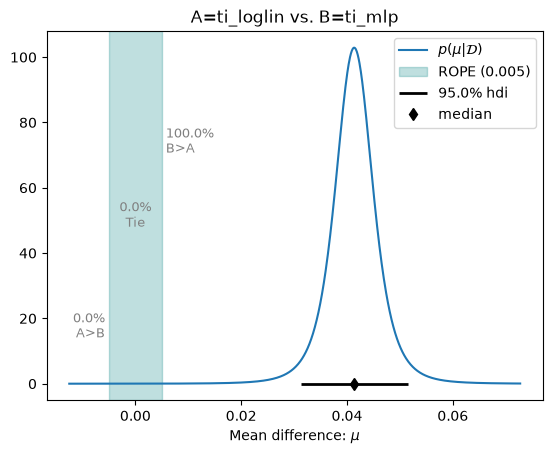

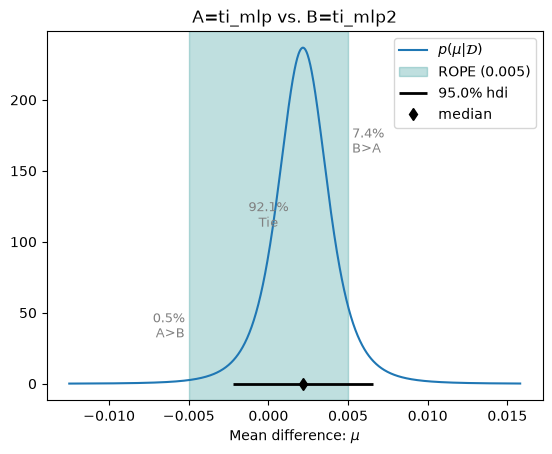

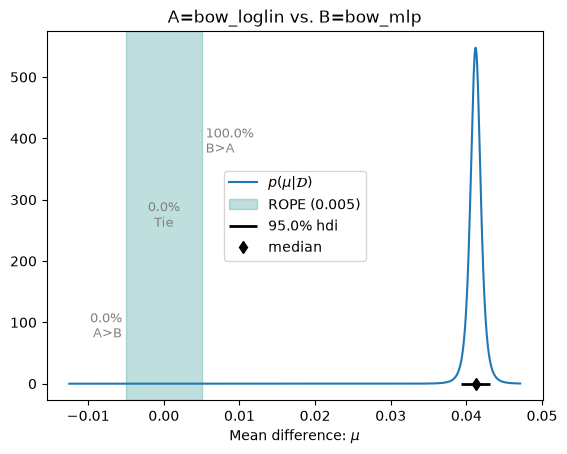

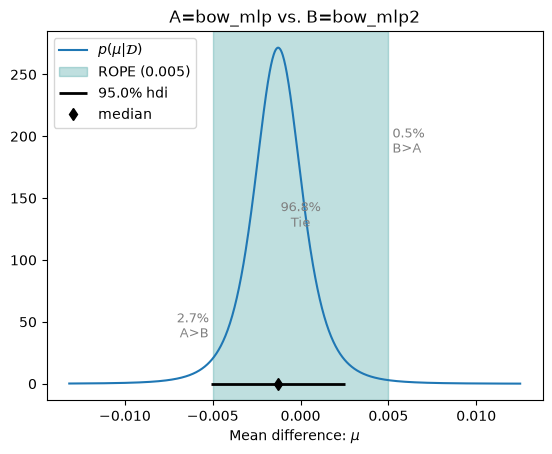

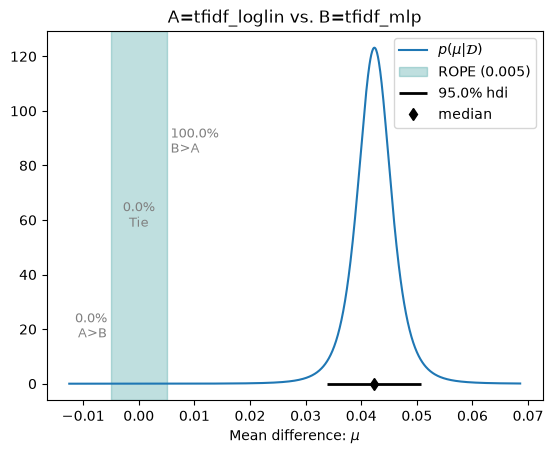

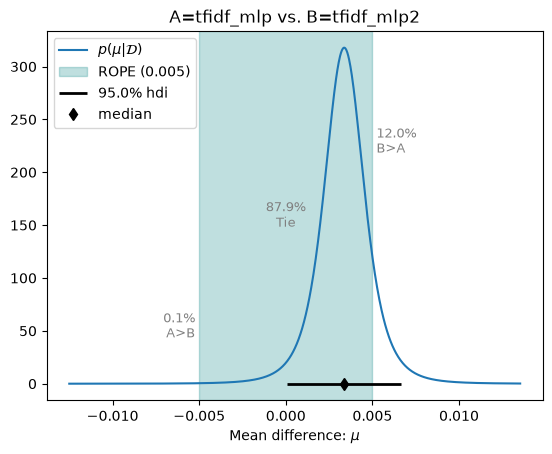

In [21]:
# Posterior plots: log-linear vs MLP and MLP vs MLP2, for each representation
for rep in ["ti", "bow", "tfidf"]:
    compare(f"{rep}_loglin", f"{rep}_mlp", plot=True)
    compare(f"{rep}_mlp", f"{rep}_mlp2", plot=True)